In [ ]:
# ==============================================================================
# CELL 1: KHỞI TẠO, TẢI DỮ LIỆU TỪ KAGGLE & XỬ LÝ LỖI #NUM!
# ==============================================================================

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("--- Đang tải Dataset 1 (Hóa - Lý): adityakadiwal/water-potability ---")
path_dataset1 = kagglehub.dataset_download("adityakadiwal/water-potability")
file_path1 = os.path.join(path_dataset1, "water_potability.csv")
df1 = pd.read_csv(file_path1)
print(f"Dataset 1 đã tải thành công. Kích thước: {df1.shape}")

print("\n--- Đang tải Dataset 2 (Vi sinh & Kim loại): mssmartypants/water-quality ---")
path_dataset2 = kagglehub.dataset_download("mssmartypants/water-quality")
file_path2 = os.path.join(path_dataset2, "waterQuality1.csv")
df2 = pd.read_csv(file_path2)
print(f"Dataset 2 đã tải thành công. Kích thước ban đầu: {df2.shape}")

# XỬ LÝ LỖI CỰC KỲ QUAN TRỌNG Ở DATASET 2:
# Thay thế giá trị chuỗi '#NUM!' bằng NaN và ép kiểu toàn bộ sang numeric cho cột 'ammonia' và 'is_safe'
print("\n--- Tiến hành xử lý lỗi chuỗi '#NUM!' trên Dataset 2 ---")

# Kiểm tra số lượng giá trị '#NUM!' trước khi xử lý
num_errors_ammonia = (df2['ammonia'] == '#NUM!').sum()
num_errors_is_safe = (df2['is_safe'] == '#NUM!').sum()
print(f"Số lượng dòng bị lỗi '#NUM!' ở cột ammonia: {num_errors_ammonia}")
print(f"Số lượng dòng bị lỗi '#NUM!' ở cột is_safe: {num_errors_is_safe}")

# Thay thế '#NUM!' bằng NaN và chuyển đổi kiểu dữ liệu thành float/int
df2['ammonia'] = pd.to_numeric(df2['ammonia'].replace('#NUM!', np.nan), errors='coerce')
df2['is_safe'] = pd.to_numeric(df2['is_safe'].replace('#NUM!', np.nan), errors='coerce')

print("\nKiểm tra lại kiểu dữ liệu sau khi sửa lỗi:")
print(df2[['ammonia', 'is_safe']].dtypes)

--- Đang tải Dataset 1 (Hóa - Lý): adityakadiwal/water-potability ---
Using Colab cache for faster access to the 'water-potability' dataset.
Dataset 1 đã tải thành công. Kích thước: (3276, 10)

--- Đang tải Dataset 2 (Vi sinh & Kim loại): mssmartypants/water-quality ---
Using Colab cache for faster access to the 'water-quality' dataset.
Dataset 2 đã tải thành công. Kích thước ban đầu: (7999, 21)

--- Tiến hành xử lý lỗi chuỗi '#NUM!' trên Dataset 2 ---
Số lượng dòng bị lỗi '#NUM!' ở cột ammonia: 3
Số lượng dòng bị lỗi '#NUM!' ở cột is_safe: 3

Kiểm tra lại kiểu dữ liệu sau khi sửa lỗi:
ammonia    float64
is_safe    float64
dtype: object



=== Tỷ lệ khuyết thiếu của Dataset 1 (Hóa - Lý) ===


,Số lượng khuyết,Tỷ lệ (%)
Sulfate,781,23.840049
ph,491,14.987790
Trihalomethanes,162,4.945055



=== Tỷ lệ khuyết thiếu của Dataset 2 (Vi sinh & Kim loại) ===


,Số lượng khuyết,Tỷ lệ (%)
ammonia,3,0.037505
is_safe,3,0.037505


/tmp/ipykernel_1038/2767120969.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df1, x='Potability', ax=axes[0], palette='Blues_d')
/tmp/ipykernel_1038/2767120969.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df2_clean_target, x='is_safe', ax=axes[1], palette='Oranges_d')


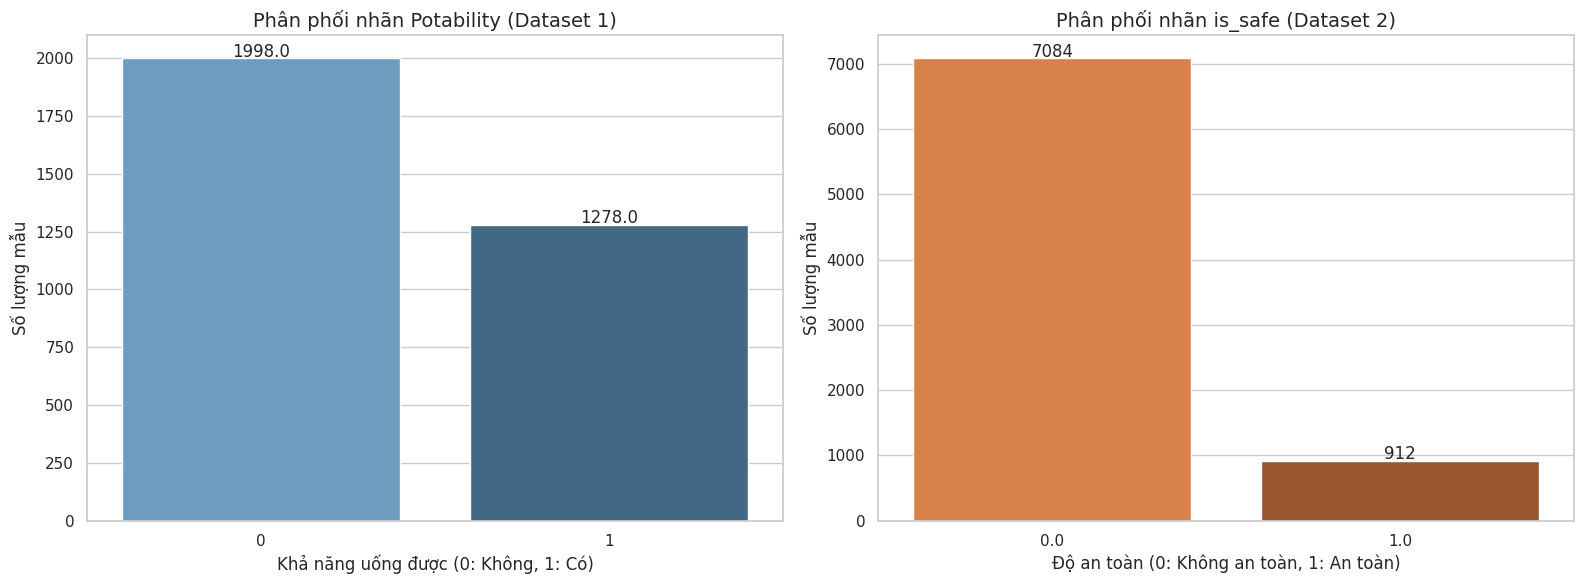

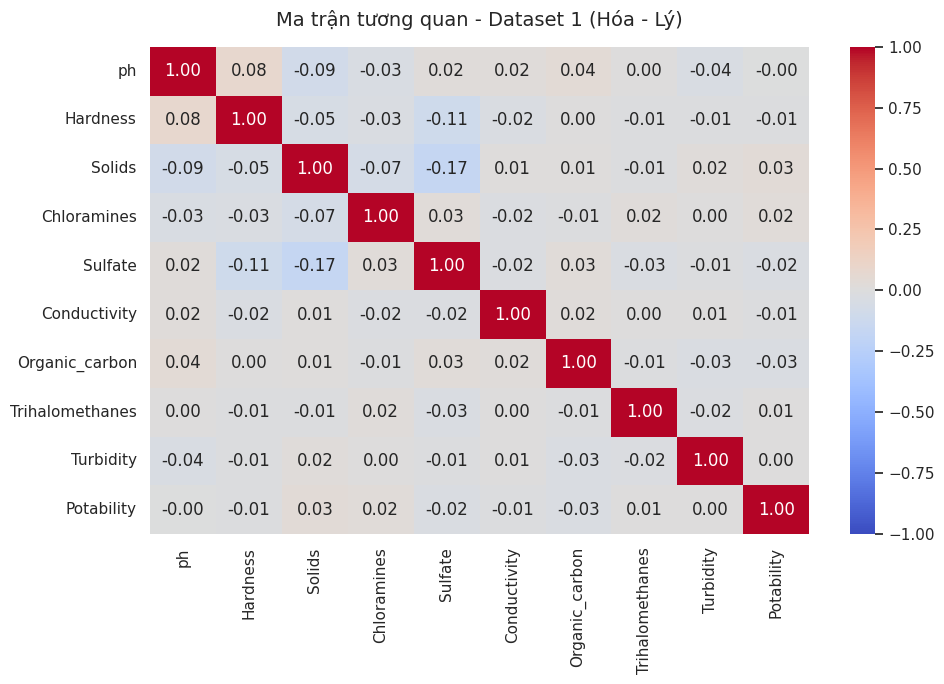

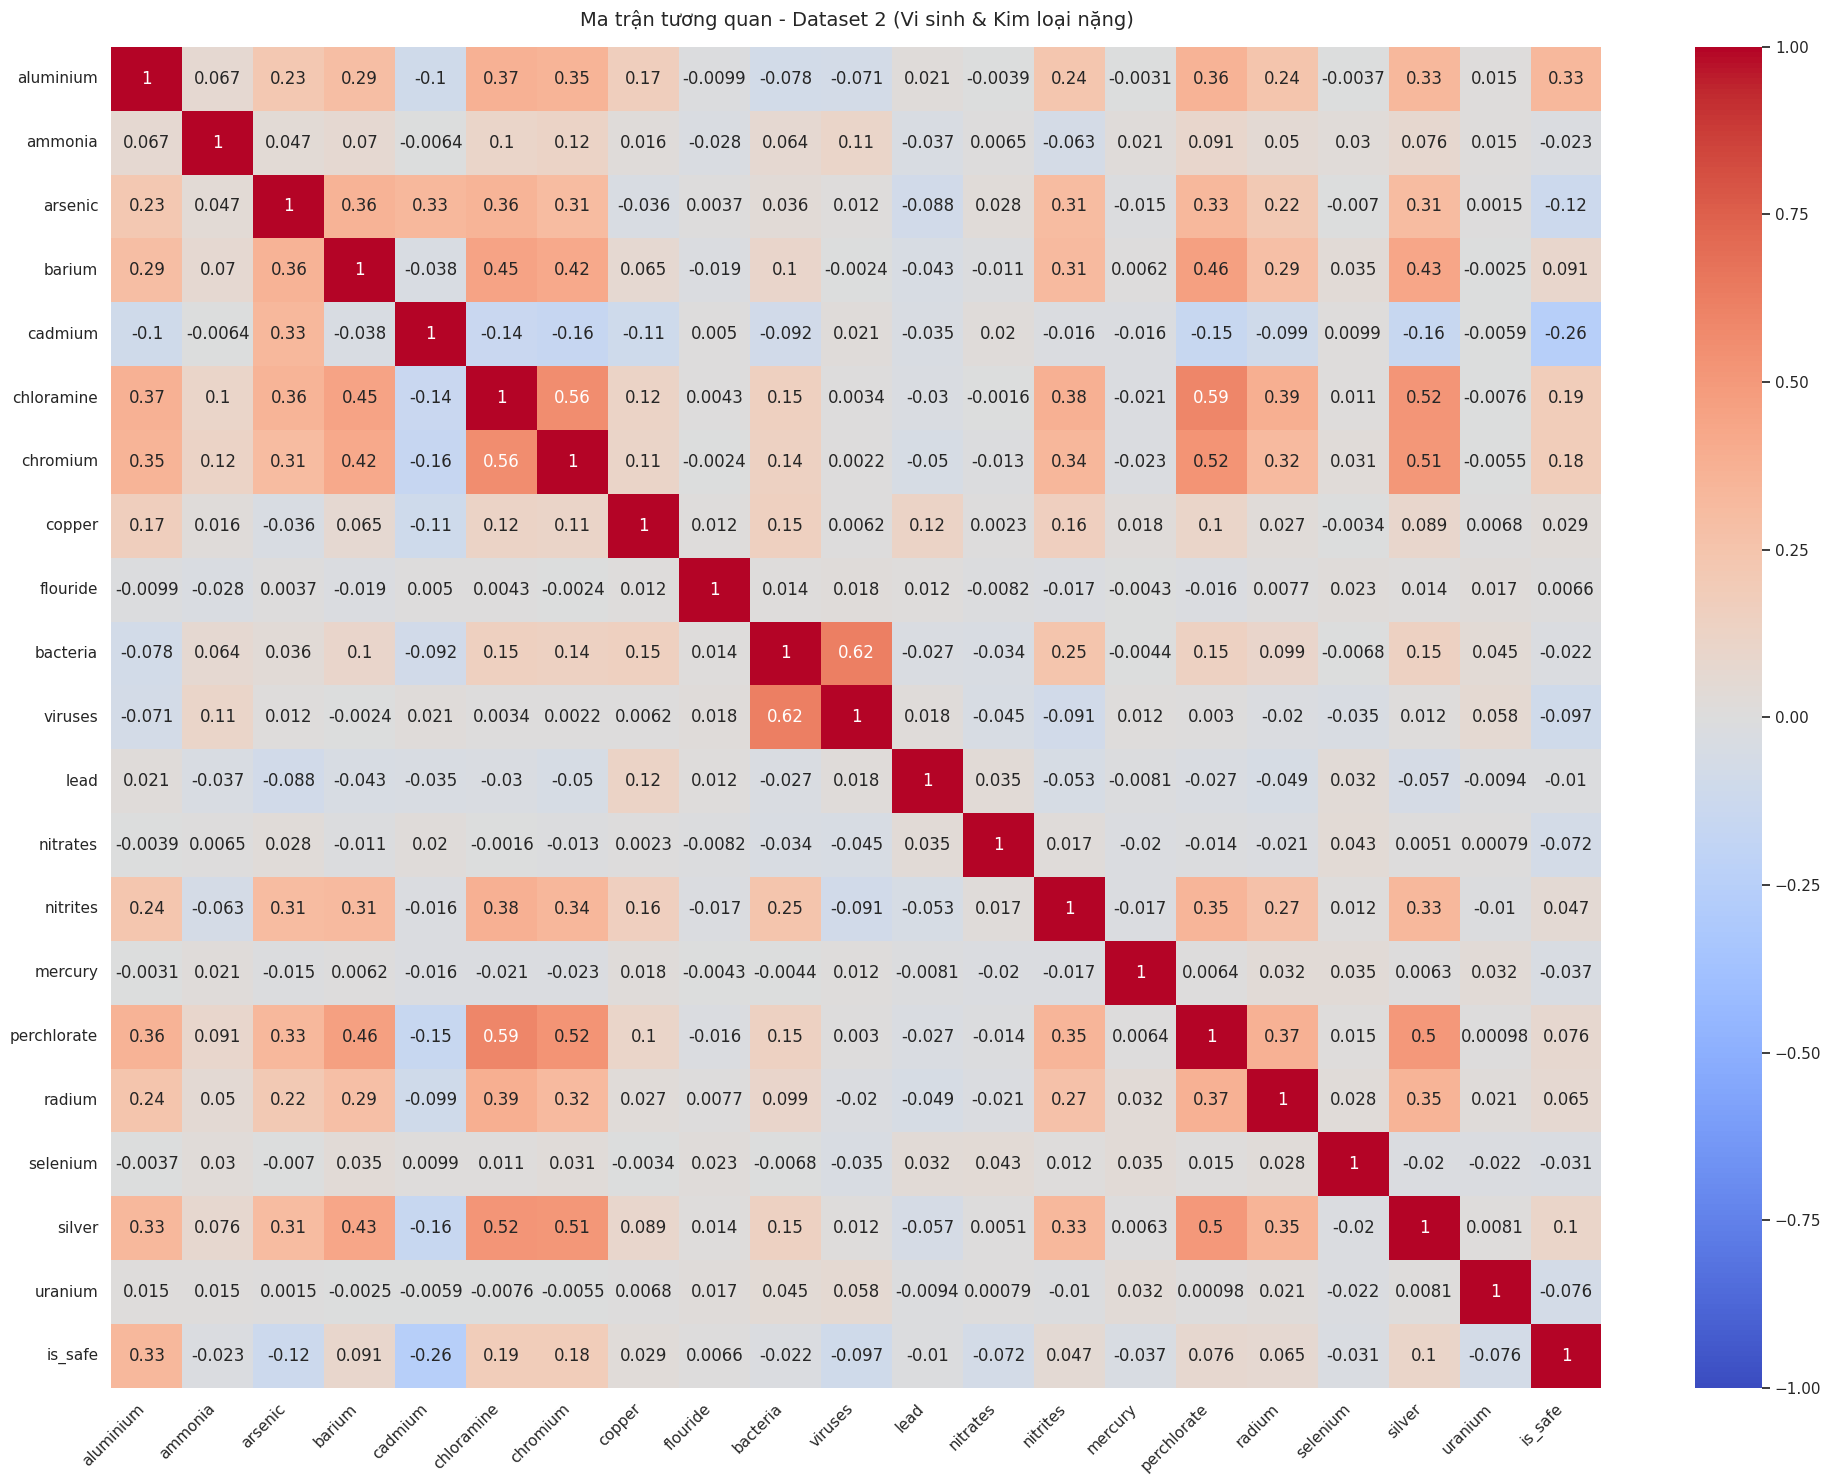

In [ ]:
# ==============================================================================
# CELL 2: KHÁM PHÁ DỮ LIỆU (EXPLORATORY DATA ANALYSIS - EDA)
# ==============================================================================

def check_missing_values(df, name):
    print(f"\n=== Tỷ lệ khuyết thiếu của {name} ===")
    missing_ratio = df.isnull().mean() * 100
    missing_df = pd.DataFrame({
        'Số lượng khuyết': df.isnull().sum(),
        'Tỷ lệ (%)': missing_ratio
    }).sort_values(by='Tỷ lệ (%)', ascending=False)
    display(missing_df[missing_df['Số lượng khuyết'] > 0])

check_missing_values(df1, "Dataset 1 (Hóa - Lý)")
check_missing_values(df2, "Dataset 2 (Vi sinh & Kim loại)")

# 2. Vẽ biểu đồ phân phối nhãn (Target Distribution) của cả hai tập dữ liệu
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.countplot(data=df1, x='Potability', ax=axes[0], palette='Blues_d')
axes[0].set_title("Phân phối nhãn Potability (Dataset 1)", fontsize=14)
axes[0].set_xlabel("Khả năng uống được (0: Không, 1: Có)")
axes[0].set_ylabel("Số lượng mẫu")
for p in axes[0].patches:
    axes[0].annotate(f'{p.get_height()}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')

# Biểu đồ cho Dataset 2 (Bỏ các dòng NaN ở nhãn để vẽ chính xác)
df2_clean_target = df2.dropna(subset=['is_safe'])
sns.countplot(data=df2_clean_target, x='is_safe', ax=axes[1], palette='Oranges_d')
axes[1].set_title("Phân phối nhãn is_safe (Dataset 2)", fontsize=14)
axes[1].set_xlabel("Độ an toàn (0: Không an toàn, 1: An toàn)")
axes[1].set_ylabel("Số lượng mẫu")
for p in axes[1].patches:
    axes[1].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center', xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()
# 3. Biểu đồ Ma trận tương quan (Correlation Heatmap) chuẩn đẹp

plt.figure(figsize=(10, 7))
sns.heatmap(df1.corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, cbar=True)
plt.title('Ma trận tương quan - Dataset 1 (Hóa - Lý)', fontsize=14, pad=15)
plt.tight_layout()
plt.show()

plt.figure(figsize=(20, 15))
# Đặt annot=False để ẩn con số dính chùm, chỉ nhìn màu sắc tương quan cho trực quan
sns.heatmap(df2_clean_target.corr(), annot=True, cmap='coolwarm', vmin=-1, vmax=1, cbar=True)
plt.title('Ma trận tương quan - Dataset 2 (Vi sinh & Kim loại nặng)', fontsize=14, pad=15)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [ ]:
def run_refined_water_benchmarks(df, target_col):
    print("==============================================================================")
    print("BẮT ĐẦU CHẠY PIPELINE ĐỐI CHUẨN (TÍCH HỢP TRÍCH XUẤT ĐẶC TRƯNG)")
    print("==============================================================================")

    # 1. Feature Engineering & Tách tập dữ liệu
    df_clean = engineer_water_features(df).dropna(subset=[target_col])
    X = df_clean.drop(columns=[target_col])
    y = df_clean[target_col].astype(int)
    feature_names = X.columns.tolist() # Lưu lại tên đặc trưng

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42, stratify=y
    )

    # 2. Tiền xử lý & Dọn dẹp ranh giới (Tomek Links)
    preprocessor = Pipeline([
        ('scaler', RobustScaler()),
        ('imputer', KNNImputer(n_neighbors=5))
    ])

    X_train_processed = preprocessor.fit_transform(X_train)
    X_test_processed = preprocessor.transform(X_test)

    tomek = TomekLinks()
    X_train_resampled, y_train_resampled = tomek.fit_resample(X_train_processed, y_train)
    scale_weight = len(y_train[y_train==0]) / len(y_train[y_train==1])

    # 3. Khởi tạo model
    models = {
        'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
        'Decision Tree': DecisionTreeClassifier(class_weight='balanced', max_depth=7, random_state=42),
        'Support Vector Machine': SVC(kernel='rbf', class_weight='balanced', probability=True, random_state=42),
        'Random Forest': RandomForestClassifier(n_estimators=300, max_depth=12, class_weight='balanced', random_state=42, n_jobs=-1),
        'XGBoost': XGBClassifier(n_estimators=300, max_depth=6, learning_rate=0.05, scale_pos_weight=scale_weight, random_state=42, eval_metric='logloss')
    }

    # 4. Huấn luyện & Lưu kết quả
    results = []
    roc_data = {}
    cm_data = {}

    for model_name, model in models.items():
        model.fit(X_train_resampled, y_train_resampled)
        y_pred = model.predict(X_test_processed)
        y_prob = model.predict_proba(X_test_processed)[:, 1]

        fpr, tpr, _ = roc_curve(y_test, y_prob)
        roc_auc = auc(fpr, tpr)
        roc_data[model_name] = (fpr, tpr, roc_auc)
        cm_data[model_name] = confusion_matrix(y_test, y_pred)

        results.append({
            'Model': model_name,
            'Test F1': f1_score(y_test, y_pred),
            'Test Recall': recall_score(y_test, y_pred),
            'Test Precision': precision_score(y_test, y_pred, zero_division=0),
            'Test Accuracy': accuracy_score(y_test, y_pred),
            'ROC-AUC': roc_auc
        })

    leaderboard_df = pd.DataFrame(results).sort_values(by='Test F1', ascending=False).reset_index(drop=True)

    from IPython.display import display
    print("\n[INFO] --- BẢNG ĐỐI CHUẨN HIỆU NĂNG TỔNG HỢP ---")
    display(leaderboard_df.round(4))

    # 5. TRỰC QUAN HÓA: BIỂU ĐỒ ROC-AUC
    plt.figure(figsize=(10, 8))
    for model_name, (fpr, tpr, roc_auc) in roc_data.items():
        plt.plot(fpr, tpr, lw=2, label=f'{model_name} (AUC = {roc_auc:.3f})')
    plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Random Guessing')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate', fontsize=12)
    plt.ylabel('True Positive Rate', fontsize=12)
    plt.title('Đường cong ROC-AUC so sánh 6 mô hình', fontsize=14, fontweight='bold')
    plt.legend(loc="lower right")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    # 6. TRỰC QUAN HÓA: MA TRẬN NHẦM LẪN (CONFUSION MATRIX)
    fig, axes = plt.subplots(2, 3, figsize=(18, 10))
    axes = axes.flatten()
    for i, (model_name, cm) in enumerate(cm_data.items()):
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[i],
                    xticklabels=['Unsafe (0)', 'Safe (1)'],
                    yticklabels=['Unsafe (0)', 'Safe (1)'],
                    annot_kws={"size": 14})
        axes[i].set_title(model_name, fontsize=12, fontweight='bold')
        axes[i].set_xlabel('Predicted Label')
        axes[i].set_ylabel('True Label')
    plt.suptitle('So sánh Ma trận nhầm lẫn giữa 6 thuật toán', fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.subplots_adjust(top=0.9)
    plt.show()

    # 7. TRỰC QUAN HÓA: FEATURE IMPORTANCE (ĐẶC TRƯNG QUAN TRỌNG)
    best_model_name = leaderboard_df.iloc[0]['Model']
    best_model = models[best_model_name]
    importances = None

    # Kiểm tra xem mô hình Top 1 có hỗ trợ trích xuất đặc trưng không
    if hasattr(best_model, 'feature_importances_'):
        importances = best_model.feature_importances_
    elif hasattr(best_model, 'coef_'):
        importances = np.abs(best_model.coef_[0]) # Dùng trị tuyệt đối của trọng số cho model Tuyến tính
    else:
        # Cơ chế Fallback: Nếu Top 1 là SVM (Không có feature importance), tìm model Cây tốt nhất tiếp theo
        for idx, row in leaderboard_df.iterrows():
            fallback_name = row['Model']
            fallback_model = models[fallback_name]
            if hasattr(fallback_model, 'feature_importances_'):
                best_model_name = fallback_name
                importances = fallback_model.feature_importances_
                print(f"\n[LƯU Ý] Mô hình Top 1 không hỗ trợ trích xuất đặc trưng. Tự động chuyển sang sử dụng {best_model_name} (Top {idx+1}) để phân tích.")
                break

    if importances is not None:
        feat_imp_df = pd.DataFrame({
            'Đặc trưng': feature_names,
            'Mức độ quan trọng': importances
        }).sort_values(by='Mức độ quan trọng', ascending=False)

        plt.figure(figsize=(10, 6))
        sns.barplot(x='Mức độ quan trọng', y='Đặc trưng', data=feat_imp_df, palette='magma')
        plt.title(f'Mức độ quan trọng của các đặc trưng\n(Trích xuất từ mô hình {best_model_name})', fontsize=15, fontweight='bold', pad=15)
        plt.xlabel('Điểm quan trọng (Feature Score)', fontsize=12)
        plt.ylabel('Tên đặc trưng', fontsize=12)

        # Thêm số liệu trực tiếp lên biểu đồ
        for index, value in enumerate(feat_imp_df['Mức độ quan trọng']):
            plt.text(value, index, f' {value:.4f}', va='center', fontsize=10)

        plt.tight_layout()
        plt.show()

    return leaderboard_df, models, preprocessor

BẮT ĐẦU CHẠY PIPELINE ĐỐI CHUẨN (TÍCH HỢP TRÍCH XUẤT ĐẶC TRƯNG)

[INFO] --- BẢNG ĐỐI CHUẨN HIỆU NĂNG TỔNG HỢP ---


,Model,Test F1,Test Recall,Test Precision,Test Accuracy,ROC-AUC
0,Decision Tree,0.5320,0.5352,0.5290,0.6326,0.6300
1,Support Vector Machine,0.5234,0.5234,0.5234,0.6280,0.6707
2,XGBoost,0.5182,0.5273,0.5094,0.6174,0.6504
3,Random Forest,0.4778,0.3984,0.5965,0.6601,0.6848
4,Logistic Regression,0.4721,0.5625,0.4068,0.5091,0.5446


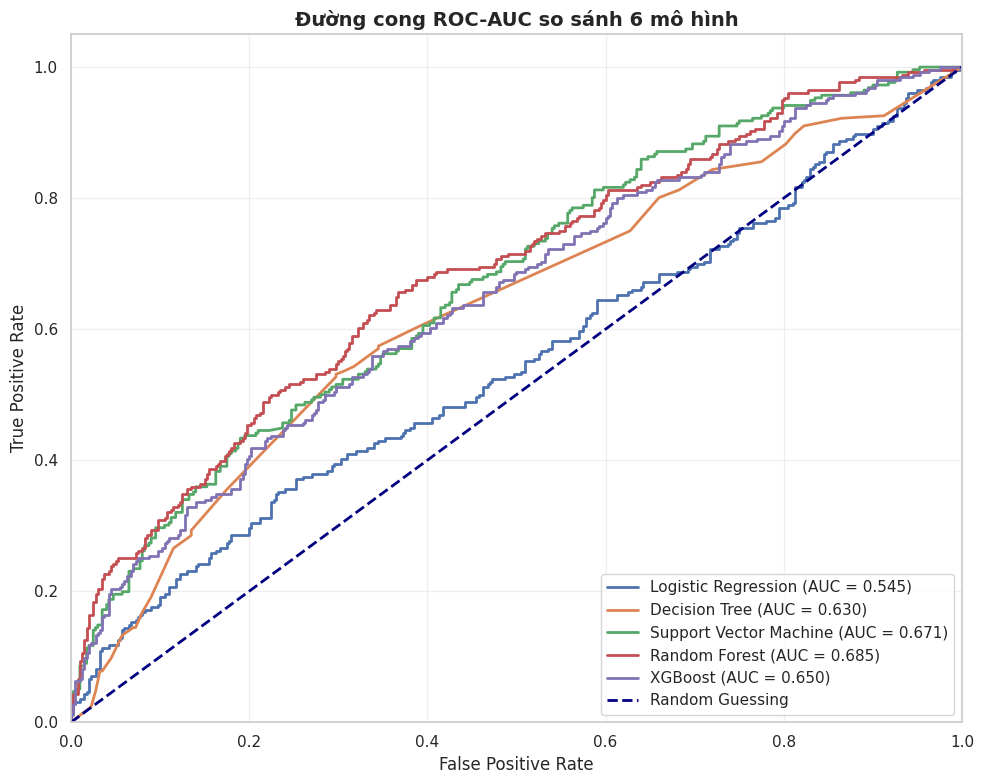

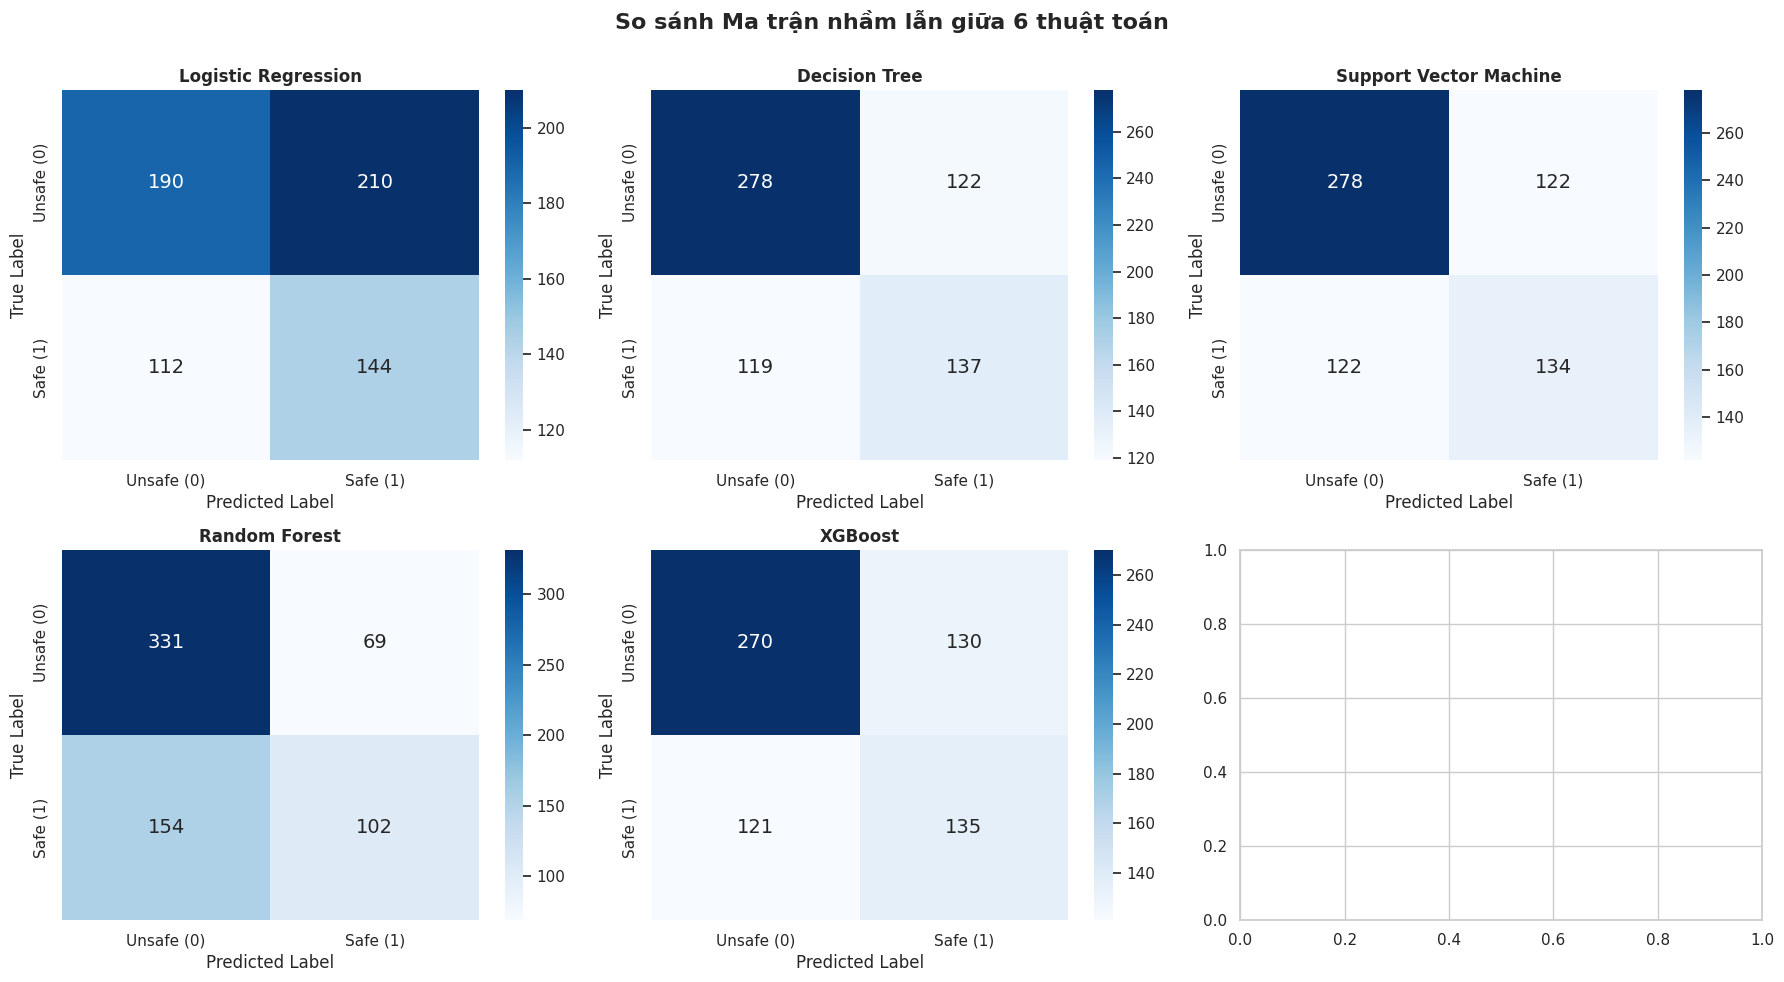

/tmp/ipykernel_1038/4253233344.py:129: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Mức độ quan trọng', y='Đặc trưng', data=feat_imp_df, palette='magma')


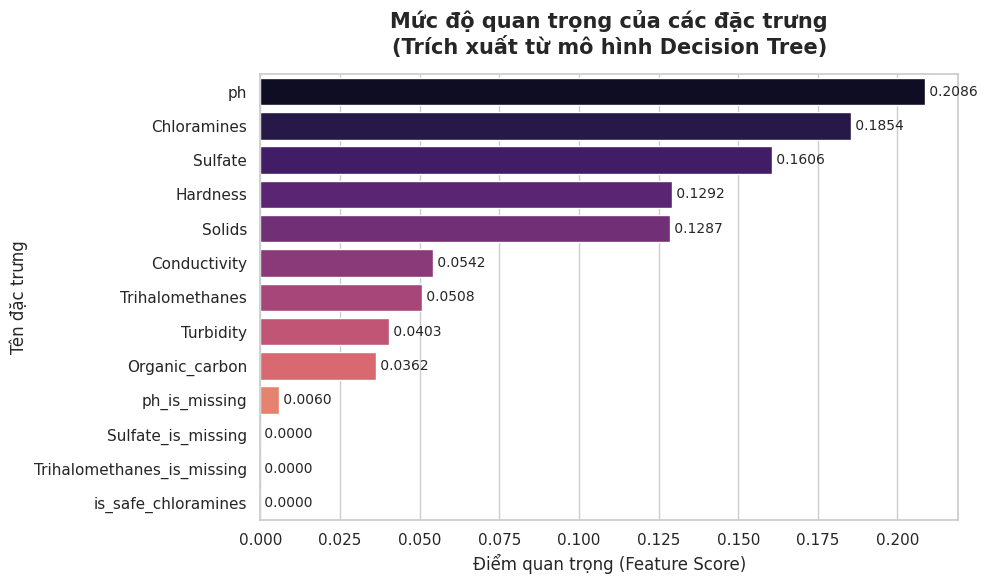

In [ ]:
leaderboard_df, trained_models, preprocessor = run_refined_water_benchmarks(df1, 'Potability')

BẮT ĐẦU CHẠY PIPELINE ĐỐI CHUẨN (TÍCH HỢP TRÍCH XUẤT ĐẶC TRƯNG)

[INFO] --- BẢNG ĐỐI CHUẨN HIỆU NĂNG TỔNG HỢP ---


,Model,Test F1,Test Recall,Test Precision,Test Accuracy,ROC-AUC
0,XGBoost,0.8595,0.8571,0.8619,0.9681,0.9862
1,Random Forest,0.7794,0.7473,0.8144,0.9519,0.9820
2,Decision Tree,0.7534,0.9231,0.6364,0.9312,0.9539
3,Support Vector Machine,0.6400,0.8352,0.5188,0.8931,0.9410
4,Logistic Regression,0.4566,0.7363,0.3309,0.8006,0.8402


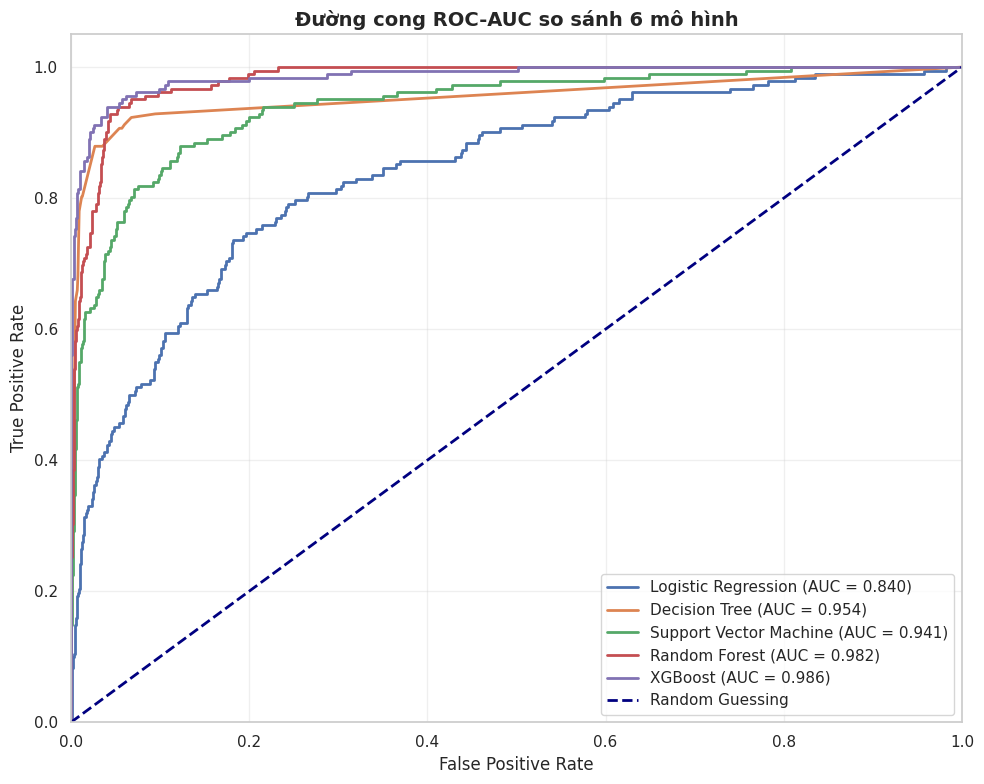

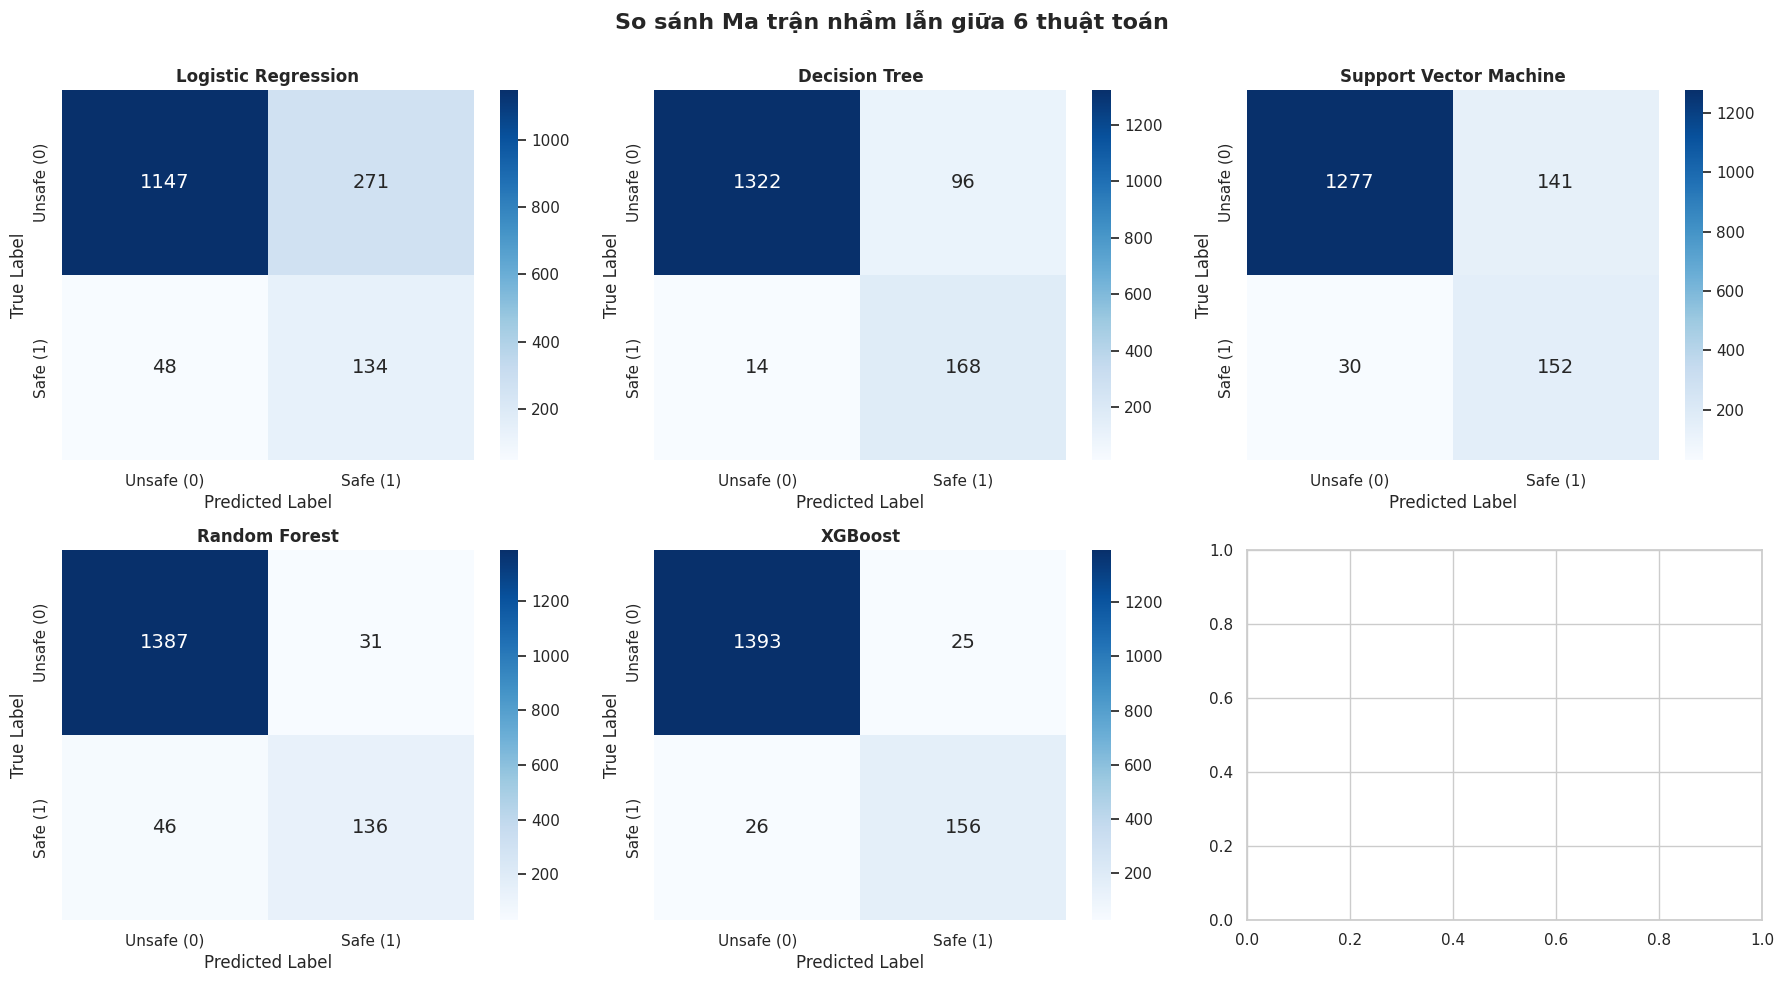

/tmp/ipykernel_1038/4253233344.py:129: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Mức độ quan trọng', y='Đặc trưng', data=feat_imp_df, palette='magma')


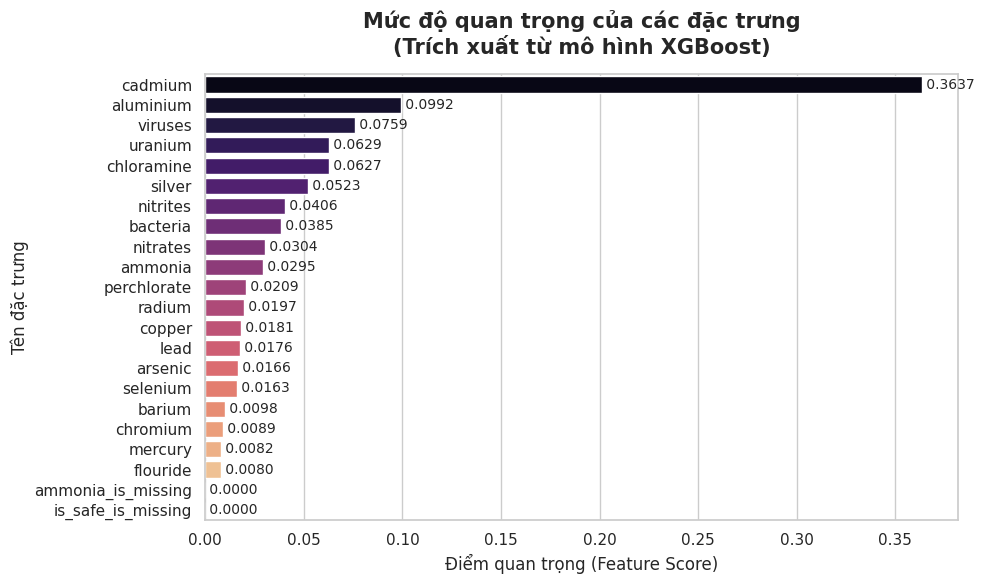

In [ ]:
# ==============================================================================
# CELL 5: THỰC THI PIPELINE TRÊN DATASET 1 (HÓA - LÝ)
# ==============================================================================

# Gọi hàm pipeline cho Dataset 2
# Cột nhãn phân loại là 'is_safe'
leaderboard_df, trained_models, preprocessor = run_refined_water_benchmarks(df2, 'is_safe')